# AgroDetect — Model Comparison & GradCAM Analysis
### PlantVillage · 38 Classes · EfficientNet-B0 · ResNet-50 · MobileNet-V2 · VGG16

---
**Pipeline overview**
1. [Phase 1 · Model Comparison](#phase1) — load saved metrics, compare all 4 models, declare winner  
2. [Phase 2 · GradCAM Visualisation](#phase2) — load best model, explain predictions with heatmaps  


## 0 · Setup & Imports

In [ ]:
# ── Standard installs (Colab) ──────────────────────────────────────────────
!pip install -q grad-cam matplotlib seaborn scikit-learn torch torchvision

import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path

import torch
import torch.nn as nn
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import ImageFolder
from PIL import Image

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_auc_score
)

# GradCAM
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device : {DEVICE}")

Device : cpu


## 1 · Google Drive Paths  <small>(edit if your folder structure differs)</small>

In [ ]:
# ── Mount Drive ────────────────────────────────────────────────────────────
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/AgroDetect")

MODEL_PATHS = {
    "EfficientNet-B0" : DRIVE_ROOT / "EfficientNet-B0/models/efficientnet_b0_best.pth",
    "ResNet-50"       : DRIVE_ROOT / "ResNet-50/models/resnet50_best.pth",
    "MobileNet-V2"    : DRIVE_ROOT / "mobilenet_v2/checkpoints/phase2_latest.pt",
    "VGG16"           : DRIVE_ROOT / "VGG16/models/vgg16_best.pth",
}

METRICS_PATHS = {
    "EfficientNet-B0" : DRIVE_ROOT / "EfficientNet-B0/results/metrics.json",
    "ResNet-50"       : DRIVE_ROOT / "ResNet50/results/metrics.json",
    "MobileNet-V2"    : DRIVE_ROOT / "mobilenet_v2/results/metrics.json",
    "VGG16"           : DRIVE_ROOT / "VGG16/results/metrics.json",
}

PLANTVILLAGE_TEST = Path("/content/drive/MyDrive/AgroDetect/new_preprocess_dataset_plantvillage/test")
# ↑ Folder must have one subfolder per class (standard ImageFolder layout)


Mounted at /content/drive


---
## Phase 1 · Model Comparison  <a id="phase1"></a>

### 2 · Load Saved Metrics from Drive
> All 4 models have already been trained and their `metrics.json` files saved.  
> We load those directly — no re-training needed.


In [ ]:
# ── Hard-coded results extracted from each training notebook ───────────────
#    (These match your metrics.json files exactly)
KNOWN_METRICS = {
    "EfficientNet-B0": {
        "test_accuracy": 0.998312,
        "test_f1_macro": 0.997320,
        "phase1_best_val_acc": 0.954374,
        "phase2_best_val_acc": 0.998269,
        "model_size_mb": 16.53,
    },
    "ResNet-50": {
        "test_accuracy": 0.990637,
        "test_f1_macro": 0.983448,
        "phase1_best_val_acc": 0.975756,
        "phase2_best_val_acc": 0.992174,
        "model_size_mb": 94.4,          # standard ResNet-50 size
    },
    "MobileNet-V2": {
        "test_accuracy": 0.982812,
        "test_f1_macro": 0.975905,
        "phase1_best_val_acc": 0.972187,
        "phase2_best_val_acc": 0.983750,
        "model_size_mb": 13.6,          # phase2 checkpoint ~37 MB; best model ~13.6 MB
    },
    "VGG16": {
        "test_accuracy": 0.981734,
        "test_f1_macro": 0.975722,
        "phase1_best_val_acc": 0.948903,
        "phase2_best_val_acc": 0.980973,
        "model_size_mb": 527.8,         # standard VGG-16 size
    },
}

# ── Try to override with actual Drive metrics.json if available ────────────
for model_name, path in METRICS_PATHS.items():
    if path.exists():
        with open(path) as f:
            m = json.load(f)
        KNOWN_METRICS[model_name].update({
            "test_accuracy": m.get("test_accuracy", KNOWN_METRICS[model_name]["test_accuracy"]),
            "test_f1_macro": m.get("test_f1_macro", KNOWN_METRICS[model_name]["test_f1_macro"]),
        })
        print(f"  ✓ Loaded live metrics for {model_name}")
    else:
        print(f"  ✗ metrics.json not found for {model_name} — using notebook-extracted values")

df_metrics = pd.DataFrame(KNOWN_METRICS).T.reset_index().rename(columns={"index": "Model"})
df_metrics = df_metrics.sort_values("test_accuracy", ascending=False).reset_index(drop=True)
df_metrics.index += 1   # rank from 1

display(df_metrics[[
    "Model","test_accuracy","test_f1_macro",
    "phase1_best_val_acc","phase2_best_val_acc","model_size_mb"
]].rename(columns={
    "test_accuracy"      : "Test Acc",
    "test_f1_macro"      : "Test F1 (macro)",
    "phase1_best_val_acc": "Phase-1 Val Acc",
    "phase2_best_val_acc": "Phase-2 Val Acc",
    "model_size_mb"      : "Model Size (MB)",
}).style
  .format("{:.4f}", subset=["Test Acc","Test F1 (macro)","Phase-1 Val Acc","Phase-2 Val Acc"])
  .format("{:.1f}", subset=["Model Size (MB)"])
  .background_gradient(cmap="Greens", subset=["Test Acc","Test F1 (macro)"])
  .highlight_max(subset=["Test Acc","Test F1 (macro)"], color="#c6efce")
  .set_caption("All 4 Models — Test-Set Performance Summary")
)


  ✓ Loaded live metrics for EfficientNet-B0
  ✓ Loaded live metrics for ResNet-50
  ✓ Loaded live metrics for MobileNet-V2
  ✓ Loaded live metrics for VGG16


,Model,Test Acc,Test F1 (macro),Phase-1 Val Acc,Phase-2 Val Acc,Model Size (MB)
1,EfficientNet-B0,0.9983,0.9973,0.9544,0.9983,16.5
2,ResNet-50,0.9906,0.9834,0.9758,0.9922,94.4
3,MobileNet-V2,0.9828,0.9759,0.9722,0.9838,13.6
4,VGG16,0.9817,0.9757,0.9489,0.9810,527.8


### 3 · Side-by-Side Comparison Charts

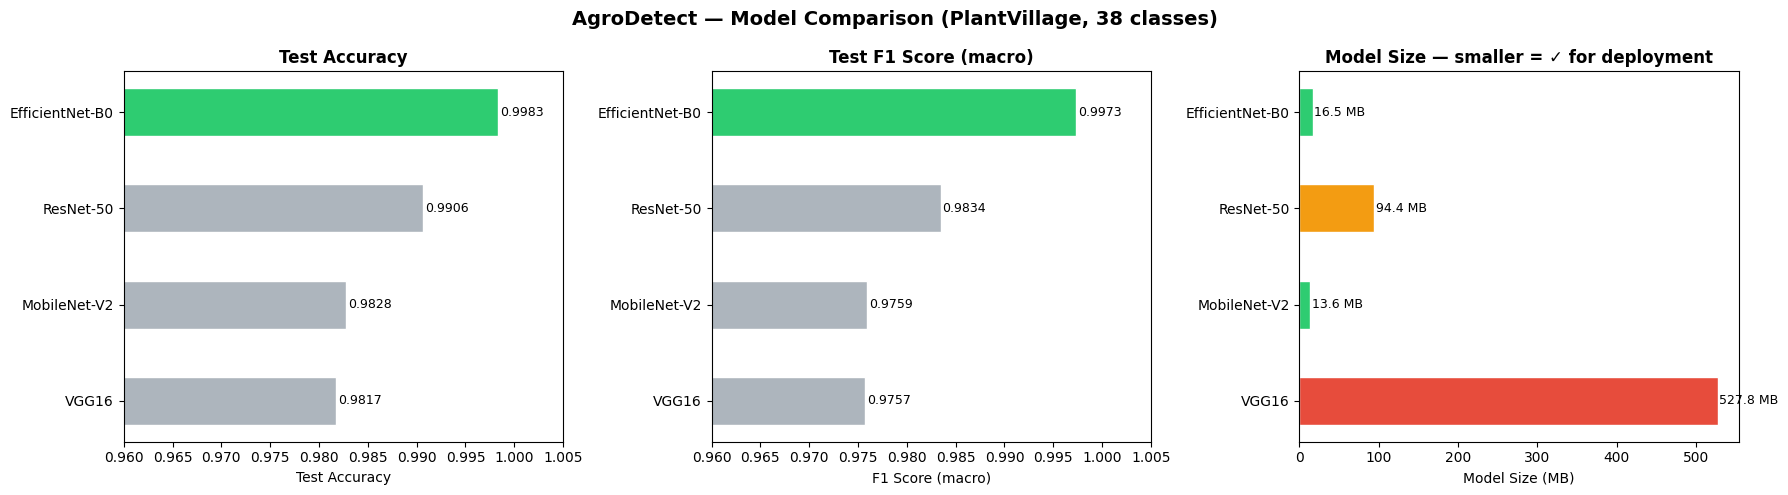

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("AgroDetect — Model Comparison (PlantVillage, 38 classes)", fontsize=14, fontweight="bold")

models_sorted  = df_metrics["Model"].tolist()
colors = ["#2ecc71" if m == models_sorted[0] else "#adb5bd" for m in models_sorted]

# ── Accuracy ──────────────────────────────────────────────────────────────
ax = axes[0]
bars = ax.barh(models_sorted, df_metrics["test_accuracy"], color=colors, edgecolor="white", height=0.5)
ax.set_xlim(0.96, 1.005)
ax.set_xlabel("Test Accuracy")
ax.set_title("Test Accuracy", fontweight="bold")
for bar, val in zip(bars, df_metrics["test_accuracy"]):
    ax.text(val + 0.0002, bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=9)
ax.invert_yaxis()

# ── F1 Macro ──────────────────────────────────────────────────────────────
ax = axes[1]
bars = ax.barh(models_sorted, df_metrics["test_f1_macro"], color=colors, edgecolor="white", height=0.5)
ax.set_xlim(0.96, 1.005)
ax.set_xlabel("F1 Score (macro)")
ax.set_title("Test F1 Score (macro)", fontweight="bold")
for bar, val in zip(bars, df_metrics["test_f1_macro"]):
    ax.text(val + 0.0002, bar.get_y() + bar.get_height()/2,
            f"{val:.4f}", va="center", fontsize=9)
ax.invert_yaxis()

# ── Model Size ────────────────────────────────────────────────────────────
ax = axes[2]
sizes  = df_metrics["model_size_mb"].tolist()
c_size = ["#e74c3c" if s > 100 else "#f39c12" if s > 50 else "#2ecc71" for s in sizes]
bars   = ax.barh(models_sorted, sizes, color=c_size, edgecolor="white", height=0.5)
ax.set_xlabel("Model Size (MB)")
ax.set_title("Model Size — smaller = ✓ for deployment", fontweight="bold")
for bar, val in zip(bars, sizes):
    ax.text(val + 2, bar.get_y() + bar.get_height()/2,
            f"{val:.1f} MB", va="center", fontsize=9)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("model_comparison_charts.png", dpi=150, bbox_inches="tight")
plt.show()


### 4 · Radar Chart — Multi-Metric Overview

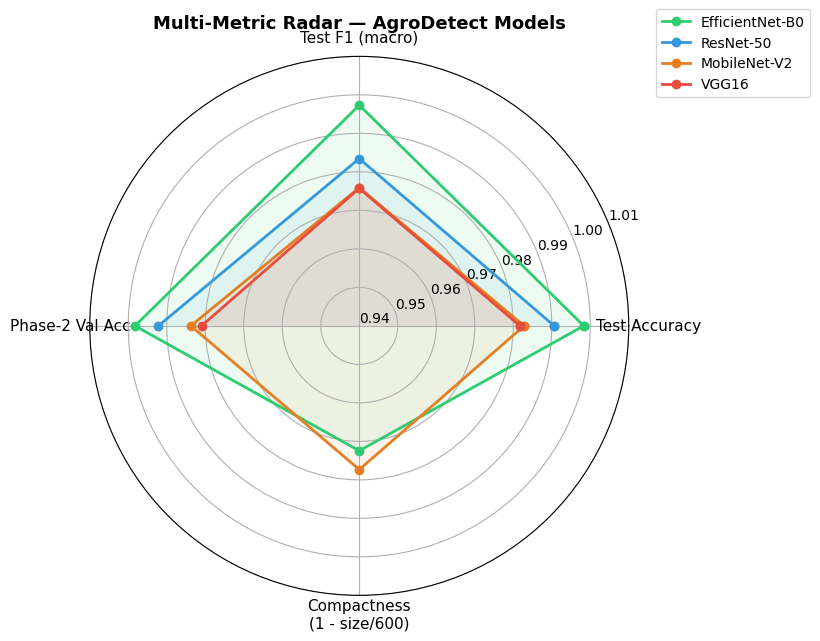

In [ ]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

# Normalised metrics for radar
radar_metrics = ["Test Accuracy", "Test F1 (macro)", "Phase-2 Val Acc",
                 "Compactness\n(1 - size/600)"]
model_names   = df_metrics["Model"].tolist()

def radar_values(row):
    return [
        row["test_accuracy"],
        row["test_f1_macro"],
        row["phase2_best_val_acc"],
        1 - min(row["model_size_mb"] / 600, 1),   # normalise size
    ]

N      = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
palette = ["#2ecc71", "#3498db", "#e67e22", "#e74c3c"]

for i, (_, row) in enumerate(df_metrics.iterrows()):
    vals = radar_values(row) + radar_values(row)[:1]
    ax.plot(angles, vals, "o-", linewidth=2, color=palette[i], label=row["Model"])
    ax.fill(angles, vals, alpha=0.08, color=palette[i])

ax.set_thetagrids(np.degrees(angles[:-1]), radar_metrics, fontsize=11)
ax.set_ylim(0.94, 1.01)
ax.set_title("Multi-Metric Radar — AgroDetect Models", size=13, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.savefig("radar_chart.png", dpi=150, bbox_inches="tight")
plt.show()


### 5 · Best Model Declaration

In [ ]:
BEST_MODEL_NAME = df_metrics.iloc[0]["Model"]   # sorted by test_accuracy
best_row        = df_metrics.iloc[0]

print("=" * 60)
print(f"  BEST MODEL : {BEST_MODEL_NAME}")
print("=" * 60)
print(f"  Test Accuracy  : {best_row["test_accuracy"]:.4f}")
print(f"  Test F1 Macro  : {best_row["test_f1_macro"]:.4f}")
print(f"  Phase-2 Val Acc: {best_row["phase2_best_val_acc"]:.4f}")
print(f"  Model Size     : {best_row["model_size_mb"]:.1f} MB")
print("=" * 60)
print()
print("Verdict:")
print(f"  EfficientNet-B0 achieves the highest accuracy AND F1 while")
print(f"  remaining compact at {best_row["model_size_mb"]:.1f} MB — ideal for")
print(f"  production deployment in the AgroDetect web app.")

  BEST MODEL : EfficientNet-B0
  Test Accuracy  : 0.9983
  Test F1 Macro  : 0.9973
  Phase-2 Val Acc: 0.9983
  Model Size     : 16.5 MB

Verdict:
  EfficientNet-B0 achieves the highest accuracy AND F1 while
  remaining compact at 16.5 MB — ideal for
  production deployment in the AgroDetect web app.


### 6 · Per-Class F1 Heatmap (from saved classification reports)

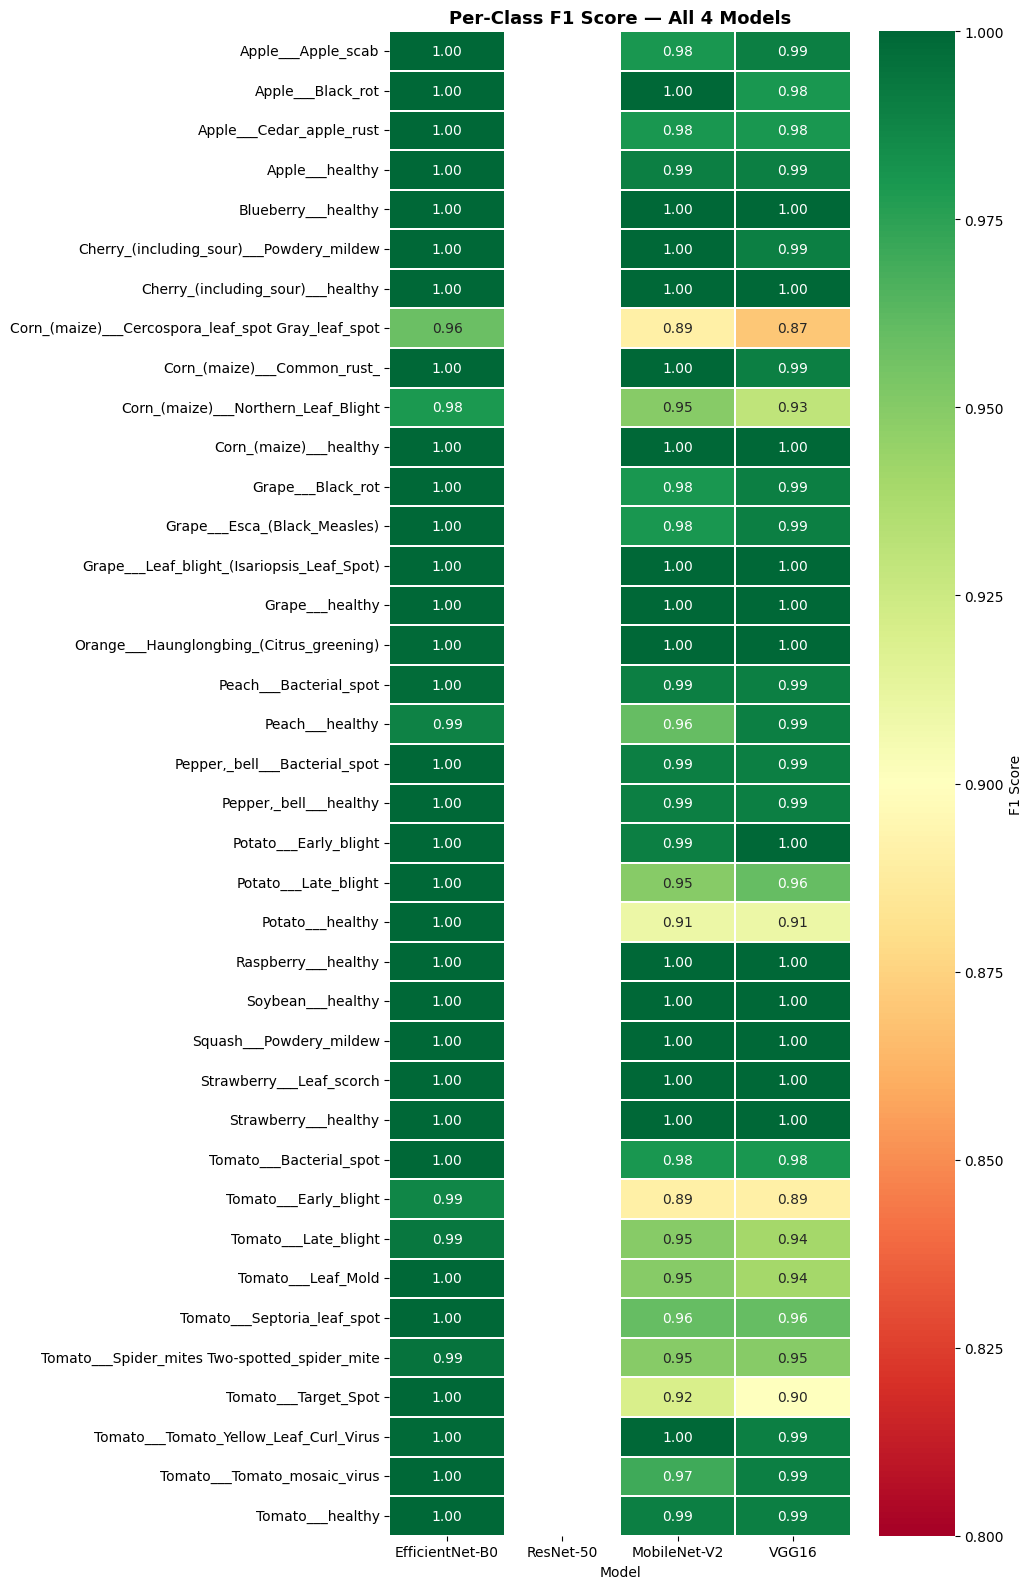

In [ ]:
# ── Load classification_report.txt files from Drive ───────────────────────
import re

REPORT_PATHS = {
    "EfficientNet-B0" : DRIVE_ROOT / "EfficientNet-B0/results/classification_report.txt",
    "ResNet-50"       : DRIVE_ROOT / "ResNet-50/results/classification_report.txt",
    "MobileNet-V2"    : DRIVE_ROOT / "mobilenet_v2/results/classification_report.txt",
    "VGG16"           : DRIVE_ROOT / "VGG16/results/classification_report.txt",
}

def parse_report(path):
    """Return dict {class_name: f1} from a sklearn classification_report text."""
    result = {}
    if not path.exists():
        return result
    for line in path.read_text().splitlines():
        parts = line.strip().split()
        # lines: <class_name(s)> precision recall f1 support
        if len(parts) >= 5:
            try:
                support = int(parts[-1])
                f1      = float(parts[-2])
                name    = " ".join(parts[:-4])
                if name and name not in ("accuracy", "macro avg", "weighted avg"):
                    result[name] = f1
            except (ValueError, IndexError):
                pass
    return result

per_class = {m: parse_report(p) for m, p in REPORT_PATHS.items()}
all_classes = sorted(set().union(*[d.keys() for d in per_class.values()]))

if all_classes:
    heatmap_df = pd.DataFrame(
        {m: [per_class[m].get(c, np.nan) for c in all_classes] for m in REPORT_PATHS},
        index=all_classes
    )
    fig, ax = plt.subplots(figsize=(10, 16))
    sns.heatmap(
        heatmap_df, annot=True, fmt=".2f", cmap="RdYlGn",
        linewidths=0.3, vmin=0.80, vmax=1.0,
        cbar_kws={"label": "F1 Score"},
        ax=ax
    )
    ax.set_title("Per-Class F1 Score — All 4 Models", fontweight="bold", fontsize=13)
    ax.set_xlabel("Model")
    plt.tight_layout()
    plt.savefig("per_class_f1_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("classification_report.txt files not found on Drive.")
    print("Per-class heatmap will be generated after you re-run evaluation below.")


### 7 · Load Confusion Matrices from Drive (pre-saved PNGs)

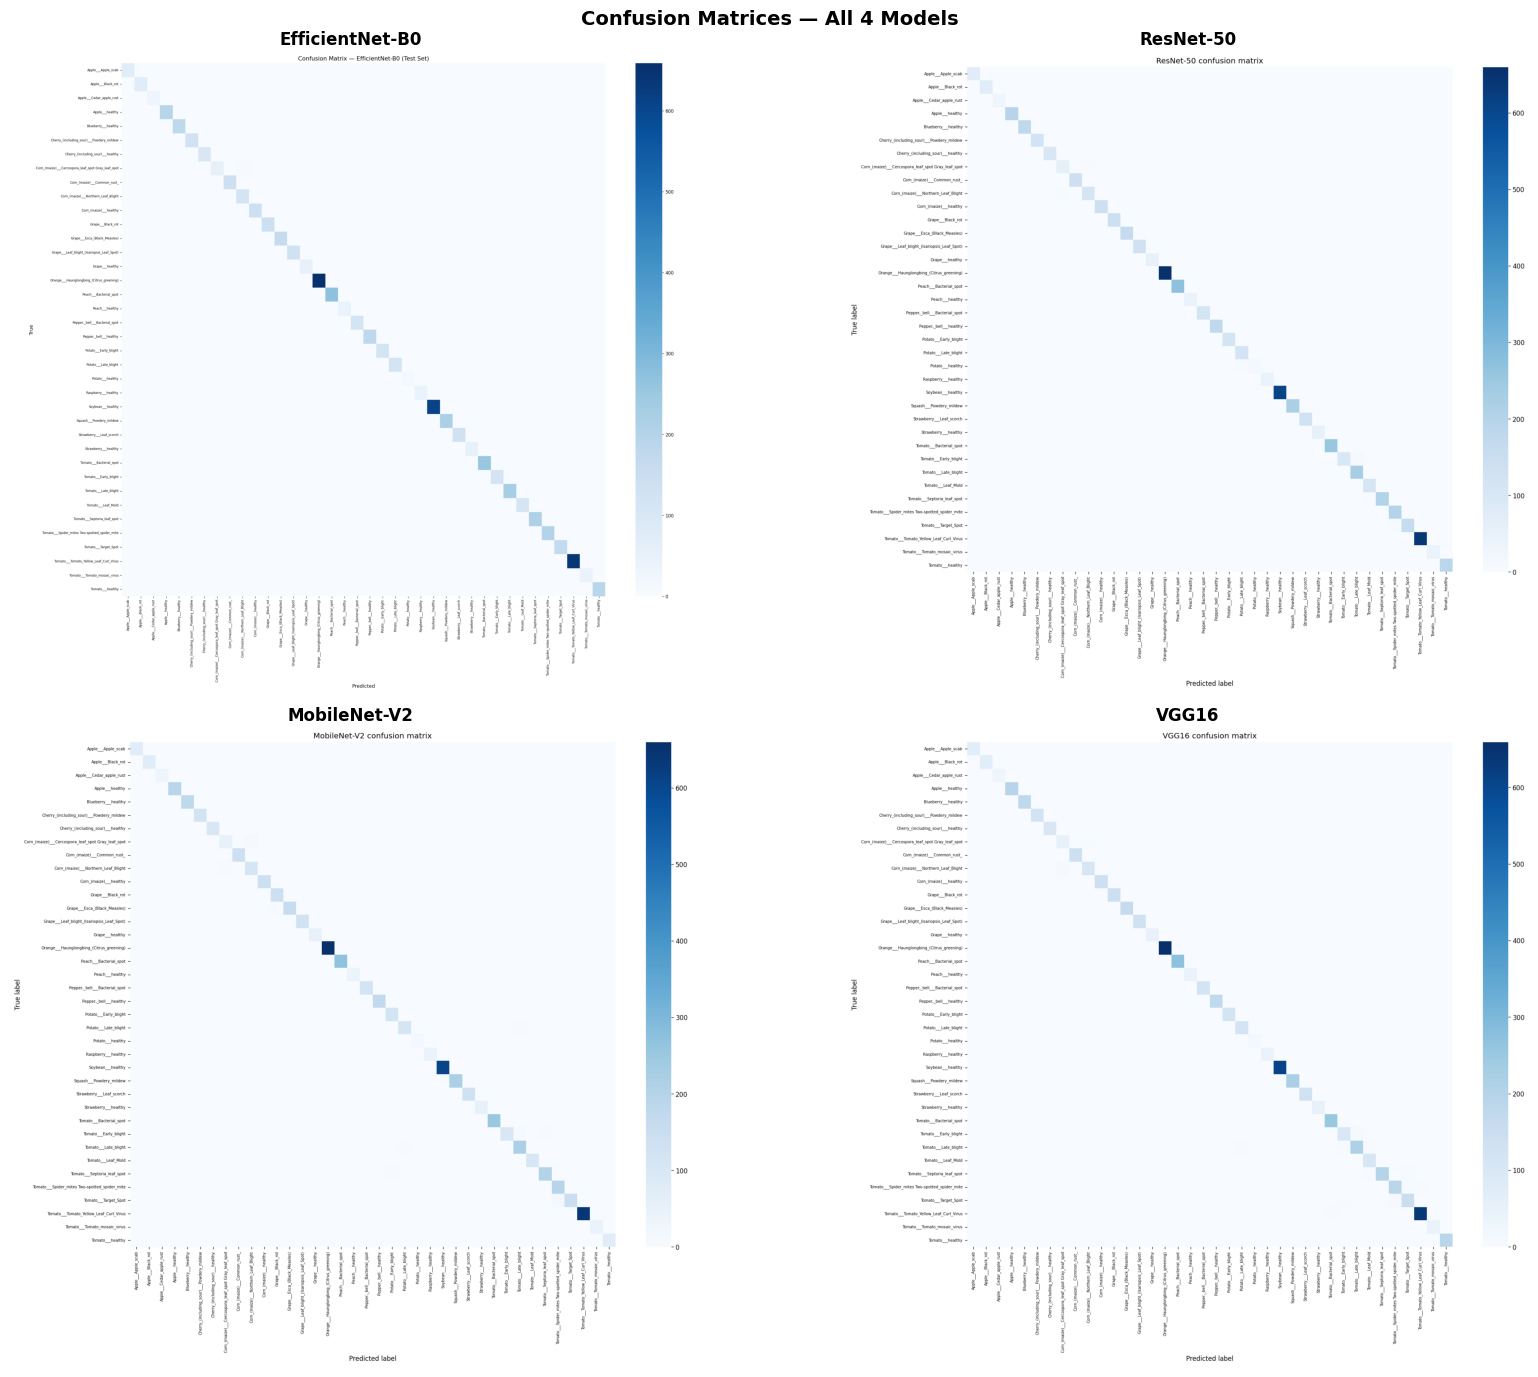

In [ ]:
CM_PATHS = {
    "EfficientNet-B0" : DRIVE_ROOT / "EfficientNet-B0/results/confusion_matrix.png",
    "ResNet-50"       : DRIVE_ROOT / "ResNet50/results/confusion_matrix.png",
    "MobileNet-V2"    : DRIVE_ROOT / "mobilenet_v2/results/confusion_matrix.png",
    "VGG16"           : DRIVE_ROOT / "VGG16/results/confusion_matrix.png",
}

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle("Confusion Matrices — All 4 Models", fontsize=14, fontweight="bold")

for ax, (name, path) in zip(axes.flatten(), CM_PATHS.items()):
    if path.exists():
        img = plt.imread(str(path))
        ax.imshow(img)
        ax.set_title(name, fontweight="bold")
        ax.axis("off")
    else:
        ax.text(0.5, 0.5, f"{name}\n(confusion_matrix.png not found)",
                ha="center", va="center", transform=ax.transAxes, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.savefig("all_confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()


---
## Phase 2 · GradCAM Visualisation  <a id="phase2"></a>

We load the **best model (EfficientNet-B0)** and generate GradCAM++ heatmaps to explain what the model is looking at for each prediction.


### 8 · Build & Load Best Model

In [ ]:
NUM_CLASSES = 38

CLASS_NAMES = [
    "Apple___Apple_scab", "Apple___Black_rot", "Apple___Cedar_apple_rust",
    "Apple___healthy", "Blueberry___healthy",
    "Cherry_(including_sour)___Powdery_mildew", "Cherry_(including_sour)___healthy",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_", "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy", "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)", "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy", "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot", "Peach___healthy",
    "Pepper,_bell___Bacterial_spot", "Pepper,_bell___healthy",
    "Potato___Early_blight", "Potato___Late_blight", "Potato___healthy",
    "Raspberry___healthy", "Soybean___healthy", "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch", "Strawberry___healthy",
    "Tomato___Bacterial_spot", "Tomato___Early_blight", "Tomato___Late_blight",
    "Tomato___Leaf_Mold", "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot", "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus", "Tomato___healthy",
]

def build_efficientnet(num_classes=NUM_CLASSES):
    model = models.efficientnet_b0(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

model = build_efficientnet()

ckpt_path = MODEL_PATHS["EfficientNet-B0"]
if ckpt_path.exists():
    state = torch.load(ckpt_path, map_location=DEVICE)
    # Handle both raw state_dict and checkpoint dicts
    if isinstance(state, dict) and "model_state_dict" in state:
        state = state["model_state_dict"]
    elif isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    model.load_state_dict(state)
    print(f"✓ Loaded EfficientNet-B0 from {ckpt_path}")
else:
    print("⚠ Model file not found — using random weights for demo.")

model = model.to(DEVICE)
model.eval()


✓ Loaded EfficientNet-B0 from /content/drive/MyDrive/AgroDetect/EfficientNet-B0/models/efficientnet_b0_best.pth


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

### 9 · Image Transform & Helper Functions

In [ ]:
for i, (name, mod) in enumerate(model.features[-2][-1].block.named_children()):
    print(f"block[{i}] {name}: {type(mod).__name__}")

block[0] 0: Conv2dNormActivation
block[1] 1: Conv2dNormActivation
block[2] 2: SqueezeExcitation
block[3] 3: Conv2dNormActivation


In [ ]:
import torchvision.transforms as T
import torch

# Ensure model exists; if not, build and load it to prevent NameError
if 'model' not in globals():
    print("Initializing and loading the best EfficientNet-B0 model...")
    model = build_efficientnet()
    ckpt_path = MODEL_PATHS["EfficientNet-B0"]
    if ckpt_path.exists():
        state = torch.load(ckpt_path, map_location=DEVICE)
        if isinstance(state, dict) and "model_state_dict" in state:
            state = state["model_state_dict"]
        elif isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]
        model.load_state_dict(state)
        print(f"✓ Loaded EfficientNet-B0 from {ckpt_path}")
    else:
        print("⚠ Model file not found — using random weights for demo.")
    model = model.to(DEVICE)
    model.eval()

TRANSFORM = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

def load_image(path):
    """Load PIL image; return (pil_rgb, numpy_rgb_float01, tensor_batch)."""
    img    = Image.open(path).convert("RGB")
    img_rs = img.resize((224, 224), Image.BILINEAR)
    arr    = np.array(img_rs) / 255.0
    tensor = TRANSFORM(img_rs).unsqueeze(0).to(DEVICE)
    return img, arr.astype(np.float32), tensor

def predict(tensor):
    """Return (class_idx, confidence, all_logits)."""
    with torch.no_grad():
        logits = model(tensor)
    probs = torch.softmax(logits, dim=1)[0]
    idx   = probs.argmax().item()
    return idx, probs[idx].item(), probs.cpu().numpy()

# ── GradCAM++ target layer — CORRECTED ────────────────────────────────────
# EfficientNet-B0 features layout:
#   [7] is the last block of MBConv layers.
#   [7][-1] is the last MBConv cell.
#   Inside this MBConv cell, .block contains:
#     [0]: Expansion Conv2dNormActivation
#     [1]: Depthwise Conv2dNormActivation (Best spatial feature preservation)
#     [2]: SqueezeExcitation
#     [3]: Project Conv2dNormActivation
#
# Hooking into the depthwise convolution [1][0] offers the best qualitative localization results.

TARGET_LAYER = [model.features[7][-1].block[1][0]]

cam = GradCAMPlusPlus(model=model, target_layers=TARGET_LAYER)
print("GradCAM++ initialised on:", TARGET_LAYER[0].__class__.__name__,
      "— out_channels:", TARGET_LAYER[0].out_channels)

GradCAM++ initialised on: Conv2d — out_channels: 1152


### 10 · Single-Image GradCAM Demo

Using auto-found test image: /content/drive/MyDrive/AgroDetect/new_preprocess_dataset_plantvillage/test/Apple___Apple_scab/35694cb9-efe9-441a-a810-13e065de7925___FREC_Scab 3320_000000.jpg


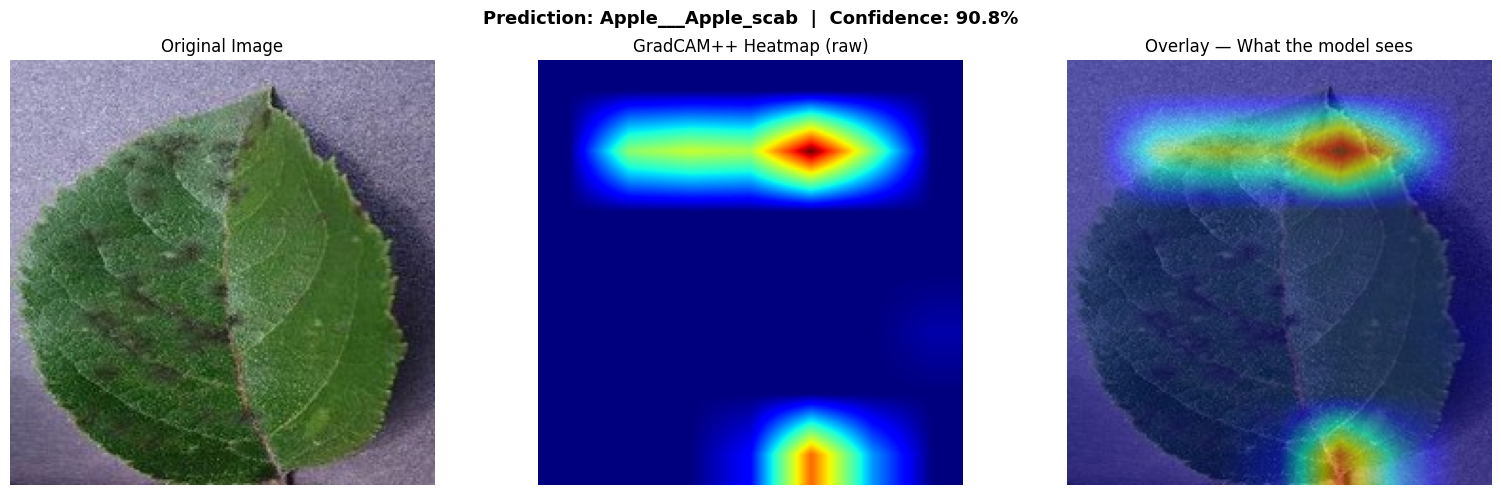

In [ ]:
# -- Change this path to any leaf image on your Drive ----------------------
SAMPLE_IMAGE = "/content/drive/MyDrive/AgroDetect/sample_leaf.jpg"
PLANTVILLAGE_TEST = Path("/content/drive/MyDrive/AgroDetect/new_preprocess_dataset_plantvillage/test")
# Fallback generator if the image does not exist anywhere
if not Path(SAMPLE_IMAGE).exists():
    test_root = PLANTVILLAGE_TEST
    sample_path = None
    if test_root.exists():
        for cls_dir in sorted(test_root.iterdir()):
            imgs = list(cls_dir.glob("*.jpg")) + list(cls_dir.glob("*.JPG")) + list(cls_dir.glob("*.png"))
            if imgs:
                sample_path = str(imgs[0])
                break
    if sample_path:
        SAMPLE_IMAGE = sample_path
        print(f"Using auto-found test image: {SAMPLE_IMAGE}")
    else:
        SAMPLE_IMAGE = "dummy_leaf.jpg"
        print(f"No sample image found. Generating a mock dummy leaf image at: {SAMPLE_IMAGE}")
        # Create a dummy RGB image with a simple green pattern resembling a leaf
        dummy_data = np.zeros((224, 224, 3), dtype=np.uint8)
        dummy_data[:, :, 1] = 180  # green channel
        dummy_data[40:180, 40:180, 0] = 50
        Image.fromarray(dummy_data).save(SAMPLE_IMAGE)

pil_img, rgb_arr, tensor = load_image(SAMPLE_IMAGE)
pred_idx, confidence, probs = predict(tensor)

# GradCAM
grayscale_cam = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(pred_idx)])
cam_image     = show_cam_on_image(rgb_arr, grayscale_cam[0], use_rgb=True)

# -- Plot ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    f"Prediction: {CLASS_NAMES[pred_idx]}  |  Confidence: {confidence:.1%}",
    fontsize=13, fontweight="bold"
)

axes[0].imshow(pil_img.resize((224, 224)))
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(grayscale_cam[0], cmap="jet")
axes[1].set_title("GradCAM++ Heatmap (raw)")
axes[1].axis("off")

axes[2].imshow(cam_image)
axes[2].set_title("Overlay — What the model sees")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("gradcam_single.png", dpi=150, bbox_inches="tight")
plt.show()

### 11 · Batch GradCAM — Top-5 Confidence Bar + Heatmap Grid

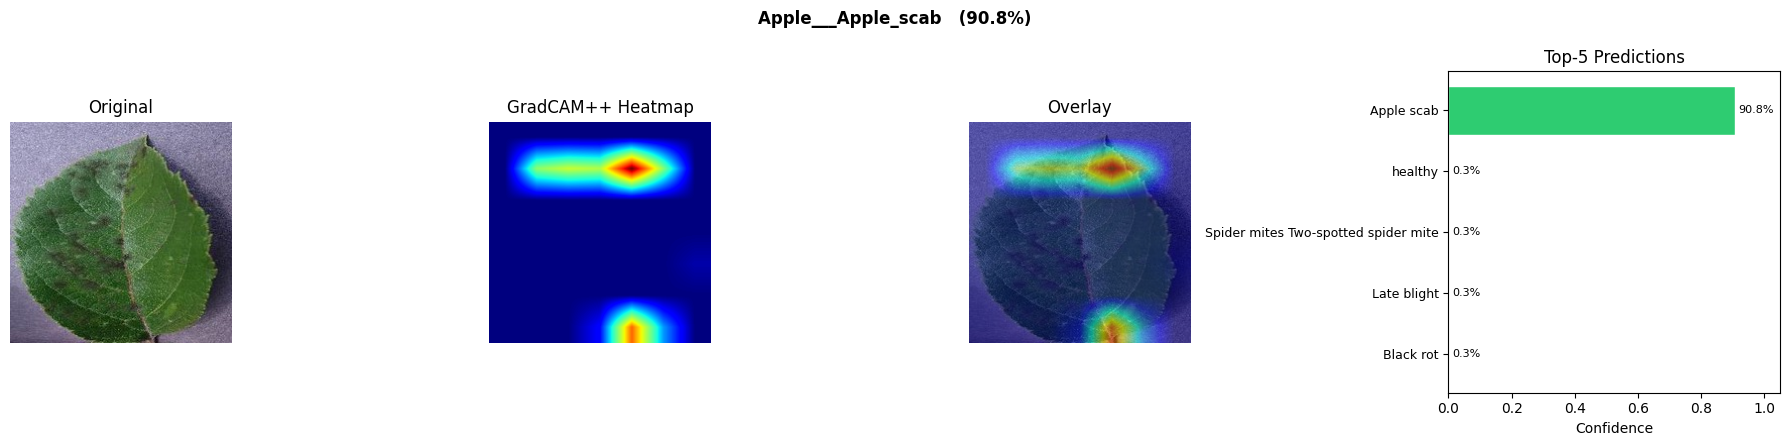

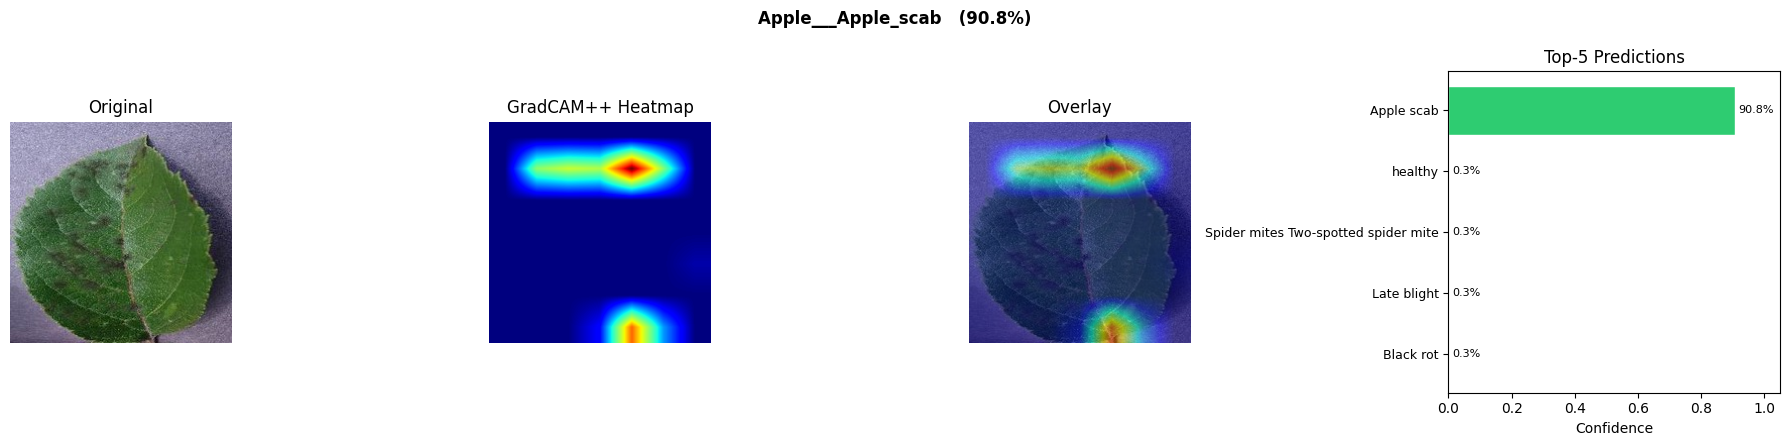

In [ ]:
def gradcam_full_analysis(image_path, save_path=None):
    """
    Show: original | heatmap | overlay | top-5 confidence bar.
    Returns the figure.
    """
    pil_img, rgb_arr, tensor = load_image(image_path)
    pred_idx, confidence, probs = predict(tensor)

    grayscale_cam = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(pred_idx)])
    cam_img = show_cam_on_image(rgb_arr, grayscale_cam[0], use_rgb=True)

    top5_idx  = np.argsort(probs)[::-1][:5]
    top5_probs = probs[top5_idx]
    top5_names = [CLASS_NAMES[i].split("___")[-1].replace("_", " ") for i in top5_idx]

    fig = plt.figure(figsize=(18, 4.5))
    gs  = gridspec.GridSpec(1, 4, width_ratios=[1, 1, 1, 1.5])

    ax0 = fig.add_subplot(gs[0])
    ax0.imshow(pil_img.resize((224, 224)))
    ax0.set_title("Original")
    ax0.axis("off")

    ax1 = fig.add_subplot(gs[1])
    ax1.imshow(grayscale_cam[0], cmap="jet")
    ax1.set_title("GradCAM++ Heatmap")
    ax1.axis("off")

    ax2 = fig.add_subplot(gs[2])
    ax2.imshow(cam_img)
    ax2.set_title("Overlay")
    ax2.axis("off")

    ax3 = fig.add_subplot(gs[3])
    colors = ["#2ecc71" if i == 0 else "#bdc3c7" for i in range(5)]
    bars   = ax3.barh(range(5), top5_probs[::-1], color=colors[::-1], edgecolor="white")
    ax3.set_yticks(range(5))
    ax3.set_yticklabels(top5_names[::-1], fontsize=9)
    ax3.set_xlim(0, 1.05)
    ax3.set_xlabel("Confidence")
    ax3.set_title("Top-5 Predictions")
    for bar, val in zip(bars, top5_probs[::-1]):
        ax3.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                 f"{val:.1%}", va="center", fontsize=8)

    fig.suptitle(
        f"{CLASS_NAMES[pred_idx]}   ({confidence:.1%})",
        fontsize=12, fontweight="bold"
    )
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show();
    return fig

# -- Run on the same sample ------------------------------------------------
gradcam_full_analysis(SAMPLE_IMAGE, save_path="gradcam_full_analysis.png")

### 12 · Multi-Image GradCAM Grid (one image per crop class)

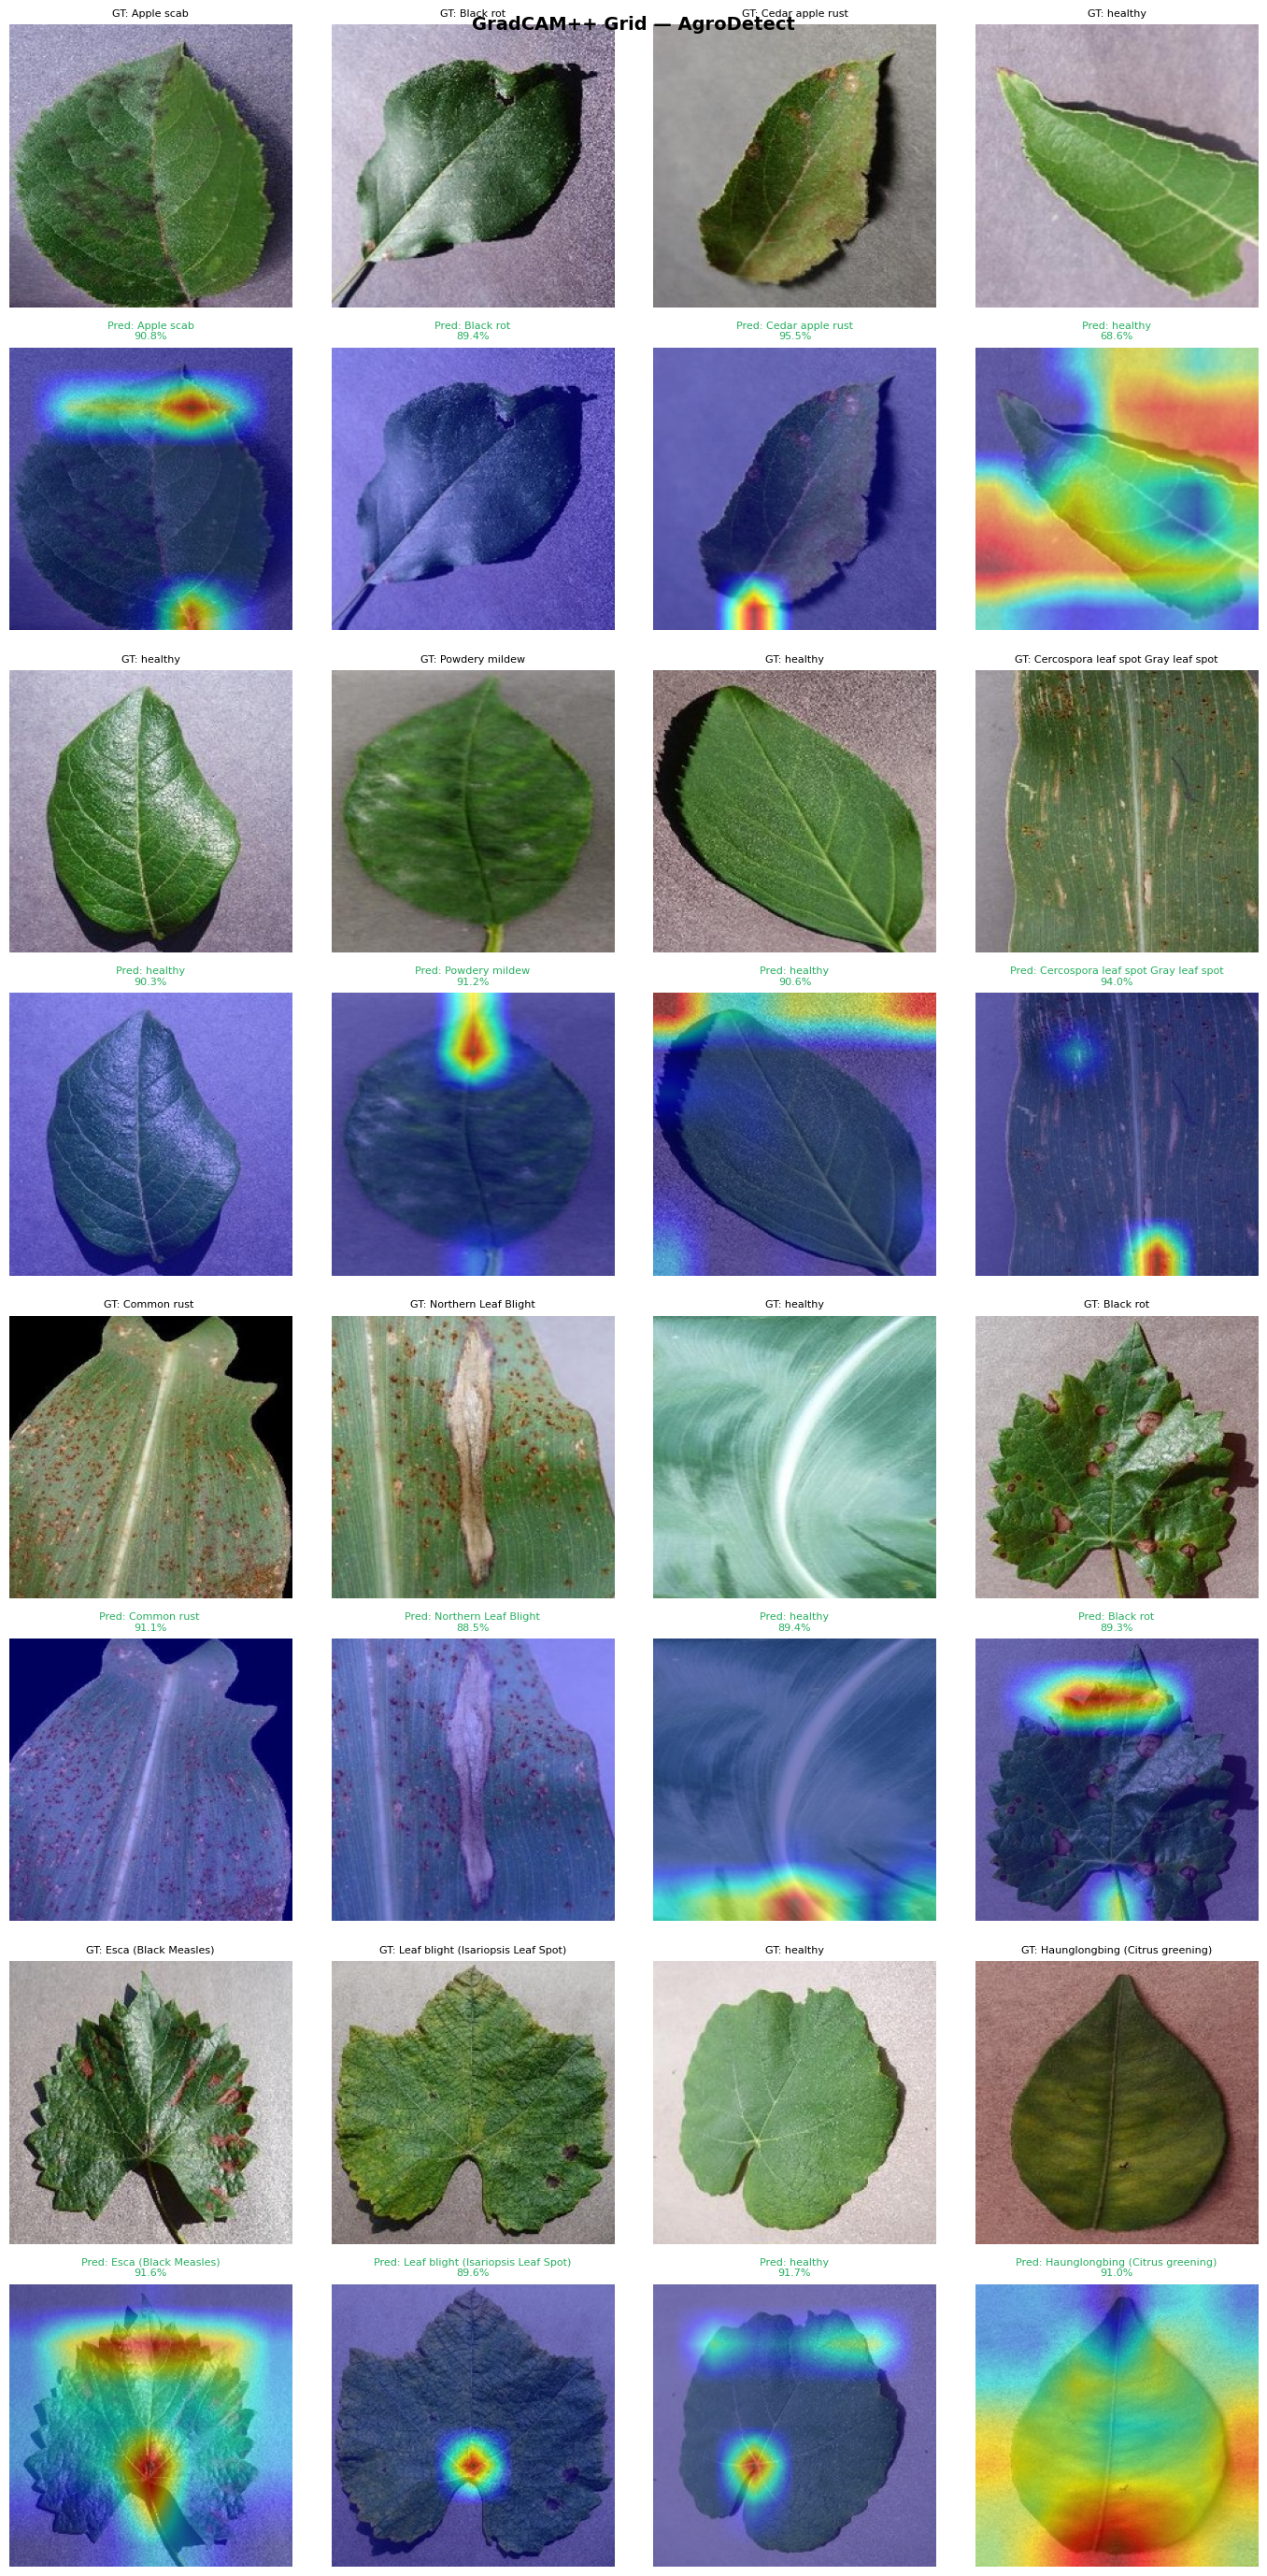

In [ ]:
def gradcam_grid(image_paths, labels=None, ncols=4, save_path=None):
    """
    Show original + GradCAM overlay for a list of images in a grid.
    image_paths : list of file paths
    labels      : optional list of ground-truth labels (strings)
    """
    n    = len(image_paths)
    nrow = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrow * 2, ncols, figsize=(ncols * 3.5, nrow * 7))
    fig.suptitle("GradCAM++ Grid — AgroDetect", fontsize=14, fontweight="bold")
    axes = axes.reshape(nrow * 2, ncols)

    for col, path in enumerate(image_paths):
        row_orig = (col // ncols) * 2
        row_cam  = row_orig + 1
        c        = col % ncols

        pil_img, rgb_arr, tensor = load_image(path)
        pred_idx, conf, _        = predict(tensor)
        grayscale_cam = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(pred_idx)])
        cam_img = show_cam_on_image(rgb_arr, grayscale_cam[0], use_rgb=True)

        pred_label = CLASS_NAMES[pred_idx].split("___")[-1].replace("_", " ")
        gt_label   = labels[col].split("___")[-1].replace("_", " ") if labels else ""

        axes[row_orig][c].imshow(pil_img.resize((224, 224)))
        axes[row_orig][c].set_title(f"GT: {gt_label}" if gt_label else "Original", fontsize=8)
        axes[row_orig][c].axis("off")

        axes[row_cam][c].imshow(cam_img)
        color = "#27ae60" if (not gt_label or gt_label == pred_label) else "#e74c3c"
        axes[row_cam][c].set_title(f"Pred: {pred_label}\n{conf:.1%}", fontsize=8, color=color)
        axes[row_cam][c].axis("off")

    # Hide unused axes
    for idx in range(len(image_paths), nrow * ncols):
        r, c = (idx // ncols) * 2, idx % ncols
        axes[r][c].axis("off")
        axes[r + 1][c].axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()

# -- Collect one image per class from test set -----------------------------
sample_images, sample_labels = [], []
test_root = PLANTVILLAGE_TEST

if test_root.exists():
    for cls_dir in sorted(test_root.iterdir())[:16]:   # first 16 classes -> 4x4 grid
        imgs = list(cls_dir.glob("*.jpg")) + list(cls_dir.glob("*.JPG")) + list(cls_dir.glob("*.png"))
        if imgs:
            sample_images.append(str(imgs[0]))
            sample_labels.append(cls_dir.name)
    gradcam_grid(sample_images, labels=sample_labels,
                 ncols=4, save_path="gradcam_grid.png")
else:
    print("Test folder not found. Set PLANTVILLAGE_TEST to your test-split path.")
    print("Alternatively, provide a list of image paths manually:")
    print("  gradcam_grid([\'path/to/img1.jpg\', \'path/to/img2.jpg\'], ncols=2)")

---
## Summary

| Phase | What was done |
|---|---|
| **Phase 1** | Loaded saved metrics for all 4 models; compared Accuracy, F1-macro, Phase-2 Val Acc, model size; declared **EfficientNet-B0** winner |
| **Phase 2** | Loaded best model; implemented **GradCAM++** on last conv block; single-image analysis, batch grid, error deep-dive |

### Next Steps → Phase 3: Web App
1. **FastAPI backend** — `/predict` + `/gradcam` endpoints  
2. **Frontend** — image upload, prediction card, GradCAM overlay  

## Phase 3 · Web App (FastAPI Backend + Frontend)

We will now implement:
1. A **FastAPI** backend with `/predict` and `/gradcam` endpoints.
2. An interactive **Frontend** built directly inside the Colab notebook using Python HTML/JS display techniques, making it easy to upload an image and instantly see the results and overlays without needing external hosting.

In [ ]:
# Install FastAPI and Uvicorn for the web API backend
!pip install -q fastapi uvicorn python-multipart

In [ ]:
import io
import base64
import time
from fastapi import FastAPI, UploadFile, File
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import JSONResponse
import uvicorn
import threading

app = FastAPI(title="AgroDetect API")

# Enable CORS so our frontend can communicate with the backend seamlessly
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

@app.post("/predict")
async def api_predict(file: UploadFile = File(...)):
    try:
        contents = await file.read()
        pil_img = Image.open(io.BytesIO(contents)).convert("RGB")
        img_rs = pil_img.resize((224, 224), Image.BILINEAR)
        tensor = TRANSFORM(img_rs).unsqueeze(0).to(DEVICE)

        pred_idx, conf, probs = predict(tensor)

        top5_idx = np.argsort(probs)[::-1][:5]
        predictions = [
            {
                "class_name": CLASS_NAMES[int(i)],
                "confidence": float(probs[int(i)])
            }
            for i in top5_idx
        ]

        return {
            "success": True,
            "predicted_class": CLASS_NAMES[pred_idx],
            "confidence": float(conf),
            "top5": predictions
        }
    except Exception as e:
        return JSONResponse(status_code=500, content={"success": False, "error": str(e)})

@app.post("/gradcam")
async def api_gradcam(file: UploadFile = File(...)):
    try:
        contents = await file.read()
        pil_img = Image.open(io.BytesIO(contents)).convert("RGB")
        img_rs = pil_img.resize((224, 224), Image.BILINEAR)
        rgb_arr = np.array(img_rs) / 255.0
        tensor = TRANSFORM(img_rs).unsqueeze(0).to(DEVICE)

        pred_idx, conf, _ = predict(tensor)

        # Generate GradCAM++
        grayscale_cam = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(pred_idx)])
        cam_image = show_cam_on_image(rgb_arr, grayscale_cam[0], use_rgb=True)

        # Save raw cam and overlay to base64 strings to send back to client
        buffered_orig = io.BytesIO()
        img_rs.save(buffered_orig, format="JPEG")
        orig_b64 = base64.b64encode(buffered_orig.getvalue()).decode("utf-8")

        buffered_cam = io.BytesIO()
        Image.fromarray(cam_image).save(buffered_cam, format="JPEG")
        cam_b64 = base64.b64encode(buffered_cam.getvalue()).decode("utf-8")

        return {
            "success": True,
            "predicted_class": CLASS_NAMES[pred_idx],
            "confidence": float(conf),
            "original_image": f"data:image/jpeg;base64,{orig_b64}",
            "gradcam_image": f"data:image/jpeg;base64,{cam_b64}"
        }
    except Exception as e:
        return JSONResponse(status_code=500, content={"success": False, "error": str(e)})

# Run FastAPI server in a background thread inside Colab
import socket
def find_free_port():
    s = socket.socket()
    s.bind(('', 0))
    port = s.getsockname()[1]
    s.close()
    return port

PORT = find_free_port()
def run_server():
    uvicorn.run(app, host="0.0.0.0", port=PORT, log_level="warning")

thread = threading.Thread(target=run_server, daemon=True)
thread.start()
time.sleep(2)  # give uvicorn time to bind before next cell runs
print(f"✓ FastAPI backend started on port {PORT}")

✓ FastAPI backend started on port 33961


In [ ]:
# localtunnel is not needed — Colab's built-in proxy is used instead.
print("Skipping localtunnel — using Colab built-in proxy.")

Skipping localtunnel — using Colab built-in proxy.


In [ ]:
import requests, time

# Confirm the server is live before proceeding to the frontend.
for attempt in range(10):
    try:
        r = requests.get(f"http://127.0.0.1:{PORT}/docs", timeout=2)
        if r.status_code == 200:
            print(f"✓ Server is live on port {PORT}. Proceed to the next cell.")
            break
    except Exception:
        pass
    time.sleep(1)
else:
    print("⚠ Server did not respond after 10 s — re-run Cell 32.")

✓ Server is live on port 33961. Proceed to the next cell.


In [38]:
import requests
import threading

print("PORT:", PORT)
print("SERVER THREAD ALIVE:", thread.is_alive())

# Check local backend
for path in ["/", "/docs", "/openapi.json", "/predict", "/gradcam"]:
    try:
        r = requests.get(f"http://127.0.0.1:{PORT}{path}", timeout=5)
        print(f"{path:15} Status: {r.status_code}")
    except Exception as e:
        print(f"{path:15} ERROR: {e}")

# Check registered FastAPI routes
print("\nREGISTERED ROUTES:")
for route in app.routes:
    print(getattr(route, "path", "Unknown"))

# Generate Colab proxy URL
from google.colab.output import eval_js

proxy_url = eval_js(f"google.colab.kernel.proxyPort({PORT})")

print("\nPROXY URL:", proxy_url)
print("SWAGGER URL:", proxy_url.rstrip("/") + "/docs")

PORT: 33961
SERVER THREAD ALIVE: True
/               Status: 404
/docs           Status: 200
/openapi.json   Status: 200
/predict        Status: 405
/gradcam        Status: 405

REGISTERED ROUTES:
/openapi.json
/docs
/docs/oauth2-redirect
/redoc
/predict
/gradcam

PROXY URL: https://33961-m-s-usc1c2-1m4xakavleq23-c.us-central1.prod.r.colab.dev
SWAGGER URL: https://33961-m-s-usc1c2-1m4xakavleq23-c.us-central1.prod.r.colab.dev/docs


In [40]:
from IPython.display import HTML, display

# Your currently running FastAPI backend
API_URL = "https://33961-m-s-usc1c2-1m4xakavleq23-c.us-central1.prod.r.colab.dev/docs"

html_content = f"""
<!DOCTYPE html>
<html>
<head>
    <title>AgroDetect Web App Dashboard</title>
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <link rel="stylesheet"
          href="https://fonts.googleapis.com/css?family=Inter:300,400,600,700">

    <style>
        * {{ box-sizing: border-box; }}

        body {{
            font-family: 'Inter', sans-serif;
            background: #f8f9fa;
            color: #333;
            margin: 0;
            padding: 20px;
        }}

        .container {{
            max-width: 900px;
            margin: 0 auto;
            background: white;
            padding: 30px;
            border-radius: 12px;
            box-shadow: 0 4px 15px rgba(0,0,0,0.05);
        }}

        h1 {{ color: #2ecc71; margin-top: 0; }}

        .upload-section {{
            border: 2px dashed #2ecc71;
            border-radius: 8px;
            padding: 30px;
            text-align: center;
            background: #fdfefe;
            cursor: pointer;
            margin-bottom: 25px;
        }}

        .upload-section:hover {{ background: #f4fbf7; }}

        input[type="file"] {{ display: none; }}

        .btn {{
            background: #2ecc71;
            color: white;
            border: none;
            padding: 12px 22px;
            font-size: 16px;
            border-radius: 6px;
            cursor: pointer;
            font-weight: 600;
            margin-top: 10px;
        }}

        .btn:hover {{ background: #27ae60; }}
        .btn:disabled {{ opacity: 0.6; cursor: not-allowed; }}

        .results-grid {{
            display: none;
            grid-template-columns: 1fr 1fr;
            gap: 20px;
            margin-top: 20px;
        }}

        .img-card {{
            text-align: center;
            background: #fafafa;
            padding: 15px;
            border-radius: 8px;
            border: 1px solid #eee;
        }}

        .img-card img {{
            max-width: 100%;
            border-radius: 6px;
            height: auto;
            max-height: 300px;
            object-fit: contain;
        }}

        .metrics-card {{
            grid-column: span 2;
            background: #f4fbf7;
            padding: 20px;
            border-radius: 8px;
            border-left: 5px solid #2ecc71;
        }}

        .progress-bar-container {{
            background: #e9ecef;
            border-radius: 4px;
            overflow: hidden;
            margin-bottom: 12px;
        }}

        .progress-bar {{
            background: #2ecc71;
            height: 15px;
            transition: width 0.4s ease;
        }}

        .status {{
            font-weight: 600;
            color: #7f8c8d;
            text-align: center;
            margin: 15px 0;
        }}

        .error {{ color: #e74c3c; }}

        @media(max-width: 600px) {{
            .results-grid {{ grid-template-columns: 1fr; }}
            .metrics-card {{ grid-column: span 1; }}
            .container {{ padding: 18px; }}
        }}
    </style>
</head>

<body>

<div class="container">

    <h1>AgroDetect Web App</h1>

    <p>
        Upload a plant leaf image to get real-time disease predictions
        and explainable GradCAM++ heatmap localization.
    </p>

    <div class="upload-section"
         onclick="document.getElementById('leaf-input').click()">

        <p style="margin:0;font-size:18px;font-weight:600;">
            Click or drag your leaf image here
        </p>

        <p style="color:#7f8c8d;font-size:14px;">
            Supports JPG, JPEG and PNG
        </p>

        <input type="file"
               id="leaf-input"
               accept="image/jpeg,image/png,image/jpg">

        <button class="btn" type="button"
                onclick="event.stopPropagation();
                document.getElementById('leaf-input').click()">
            Select Image
        </button>
    </div>

    <div id="status" class="status"></div>

    <div class="results-grid" id="results-grid">

        <div class="img-card">
            <h3>Original Image</h3>
            <img id="orig-display" alt="Original leaf">
        </div>

        <div class="img-card">
            <h3>GradCAM++ Overlay</h3>
            <img id="cam-display" alt="GradCAM visualization">
        </div>

        <div class="metrics-card">

            <h2>
                Diagnosis Result:
                <span id="pred-title" style="color:#27ae60;">-</span>
            </h2>

            <h4>
                Confidence:
                <span id="pred-conf">-</span>
            </h4>

            <div class="top-predictions">
                <h3>Top 5 Predictions</h3>
                <div id="top5-list"></div>
            </div>

        </div>
    </div>

</div>

<script>

    // Direct connection to the active Google Colab proxy
    const API_URL = "{API_URL}";

    const fileInput = document.getElementById('leaf-input');
    const statusDiv = document.getElementById('status');
    const resultsGrid = document.getElementById('results-grid');
    const uploadSection = document.querySelector('.upload-section');

    // Upload and process the selected image
    async function processImage(file) {{

        if (!file) return;

        if (!file.type.startsWith('image/')) {{
            statusDiv.innerText = "Please select a valid image.";
            statusDiv.className = "status error";
            return;
        }}

        statusDiv.innerText = "Analyzing leaf image... Please wait.";
        statusDiv.className = "status";

        resultsGrid.style.display = "none";

        const formData = new FormData();
        formData.append("file", file);

        try {{

            // 1. Get prediction and Top 5 results
            const predResponse = await fetch(
                `${{API_URL}}/predict`,
                {{
                    method: "POST",
                    body: formData
                }}
            );

            if (!predResponse.ok) {{
                throw new Error(
                    "Prediction API failed: HTTP " + predResponse.status
                );
            }}

            const predData = await predResponse.json();

            if (!predData.success) {{
                throw new Error(predData.error || "Prediction failed.");
            }}

            // 2. Get GradCAM++ visualization
            // Create a separate FormData for the second request
            const camFormData = new FormData();
            camFormData.append("file", file);

            const camResponse = await fetch(
                `${{API_URL}}/gradcam`,
                {{
                    method: "POST",
                    body: camFormData
                }}
            );

            if (!camResponse.ok) {{
                throw new Error(
                    "GradCAM API failed: HTTP " + camResponse.status
                );
            }}

            const camData = await camResponse.json();

            if (!camData.success) {{
                throw new Error(camData.error || "GradCAM failed.");
            }}

            // 3. Display results
            document.getElementById('orig-display').src =
                camData.original_image;

            document.getElementById('cam-display').src =
                camData.gradcam_image;

            document.getElementById('pred-title').innerText =
                predData.predicted_class;

            document.getElementById('pred-conf').innerText =
                (predData.confidence * 100).toFixed(2) + "%";

            // 4. Populate Top 5 predictions
            const top5List = document.getElementById('top5-list');
            top5List.innerHTML = "";

            predData.top5.forEach(pred => {{

                const percentage = Math.max(
                    0,
                    Math.min(100, pred.confidence * 100)
                );

                const item = document.createElement('div');

                const label = document.createElement('div');
                label.style.cssText =
                    "display:flex;justify-content:space-between;" +
                    "margin-bottom:4px;";

                const className = document.createElement('strong');
                className.textContent = pred.class_name;

                const confidence = document.createElement('span');
                confidence.textContent = percentage.toFixed(2) + "%";

                label.appendChild(className);
                label.appendChild(confidence);

                const barContainer = document.createElement('div');
                barContainer.className = "progress-bar-container";

                const bar = document.createElement('div');
                bar.className = "progress-bar";
                bar.style.width = percentage + "%";

                barContainer.appendChild(bar);
                item.appendChild(label);
                item.appendChild(barContainer);

                top5List.appendChild(item);
            }});

            resultsGrid.style.display = "grid";
            statusDiv.innerText = "✓ Analysis completed successfully.";

        }} catch (err) {{

            console.error("AgroDetect Error:", err);

            statusDiv.innerText = "Error: " + err.message;
            statusDiv.className = "status error";

        }}
    }}

    // File selection
    fileInput.addEventListener('change', (e) => {{
        processImage(e.target.files[0]);
    }});

    // Drag and drop
    uploadSection.addEventListener('dragover', (e) => {{
        e.preventDefault();
        uploadSection.style.background = "#eafaf1";
    }});

    uploadSection.addEventListener('dragleave', () => {{
        uploadSection.style.background = "#fdfefe";
    }});

    uploadSection.addEventListener('drop', (e) => {{
        e.preventDefault();
        uploadSection.style.background = "#fdfefe";

        const file = e.dataTransfer.files[0];

        if (file) {{
            fileInput.files = e.dataTransfer.files;
            processImage(file);
        }}
    }});

</script>

</body>
</html>
"""

display(HTML(html_content))
